# Evaluacion parcial 2 Deep Learning, clasificacion de personajes
Seccion: 007D
Integrante: Angel Pimiento

#Extracción y Carga de Datos

In [ ]:
!rm -rf /content/simpsons /content/simpsons_testset

In [ ]:
!tar -xzf /content/simpsons_train.tar.gz -C /content/
!tar -xzf /content/simpsons_test.tar.gz -C /content/

In [ ]:
import os

train_dir = "/content/simpsons"
conteo_personajes = {}

# Contar imágenes por cada subcarpeta
for personaje in os.listdir(train_dir):
    ruta_personaje = os.path.join(train_dir, personaje)
    if os.path.isdir(ruta_personaje):
        num_imagenes = len([img for img in os.listdir(ruta_personaje) if img.endswith("jpg")])
        conteo_personajes[personaje] = num_imagenes

# Ordenar de mayor a menor cantidad de fotos
top_18 = sorted(conteo_personajes.items(), key=lambda x: x[1], reverse=True)[:18]

# Mostrar resultados
print("--- TOP 18 PERSONAJES REALES ---")
for i, (personaje, cantidad) in enumerate(top_18):
    print(f"{i}: '{personaje}' -> {cantidad} fotos")

--- TOP 18 PERSONAJES REALES ---
0: 'homer_simpson' -> 2246 fotos
1: 'ned_flanders' -> 1454 fotos
2: 'moe_szyslak' -> 1452 fotos
3: 'lisa_simpson' -> 1354 fotos
4: 'bart_simpson' -> 1342 fotos
5: 'marge_simpson' -> 1291 fotos
6: 'krusty_the_clown' -> 1206 fotos
7: 'principal_skinner' -> 1194 fotos
8: 'charles_montgomery_burns' -> 1193 fotos
9: 'milhouse_van_houten' -> 1079 fotos
10: 'chief_wiggum' -> 986 fotos
11: 'abraham_grampa_simpson' -> 913 fotos
12: 'sideshow_bob' -> 877 fotos
13: 'apu_nahasapeemapetilon' -> 623 fotos
14: 'kent_brockman' -> 498 fotos
15: 'comic_book_guy' -> 469 fotos
16: 'edna_krabappel' -> 457 fotos
17: 'nelson_muntz' -> 358 fotos


In [ ]:
import cv2
import os
import glob
import numpy as np

# Mapeo de los 18 personajes con más imágenes
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}

# Tamaño estandarizado para las imágenes
IMG_SIZE = 64

In [ ]:
#Funciones de extracción a arrays (Numpy)
#El set de entrenamiento organiza las imágenes en subcarpetas por personaje pero los archivos no tienen nombre, mientras que el set de prueba contiene todas las imágenes juntas pero nombradas

#etiqueta los archivos por el nombre de la carpeta y devuelve un array para entrenar
def load_train_set(dirname, map_characters):
    X_train, y_train = [], []
    for label, character in map_characters.items():
        folder = os.path.join(dirname, character)
        for image_name in os.listdir(folder):
            if image_name.endswith("jpg"):
                img = cv2.imread(os.path.join(folder, image_name))
                X_train.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
                y_train.append(label)
    return np.array(X_train), np.array(y_train)
#etiqueta los archivos del test por el nombre, devuelve un array para test
def load_test_set(dirname, map_characters):
    X_test, y_test = [], []
    reverse_dict = {v: k for k, v in map_characters.items()}
    for filename in glob.glob(dirname + '/*.*'):
        char_name = "_".join(filename.split('/')[-1].split('_')[:-1])
        if char_name in reverse_dict:
            img = cv2.imread(filename)
            X_test.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
            y_test.append(reverse_dict[char_name])
    return np.array(X_test), np.array(y_test)

# Ejecutar carga de datos
X_train, y_train = load_train_set("/content/simpsons", MAP_CHARACTERS)
X_test, y_test = load_test_set("/content/simpsons_testset", MAP_CHARACTERS)

# EDA

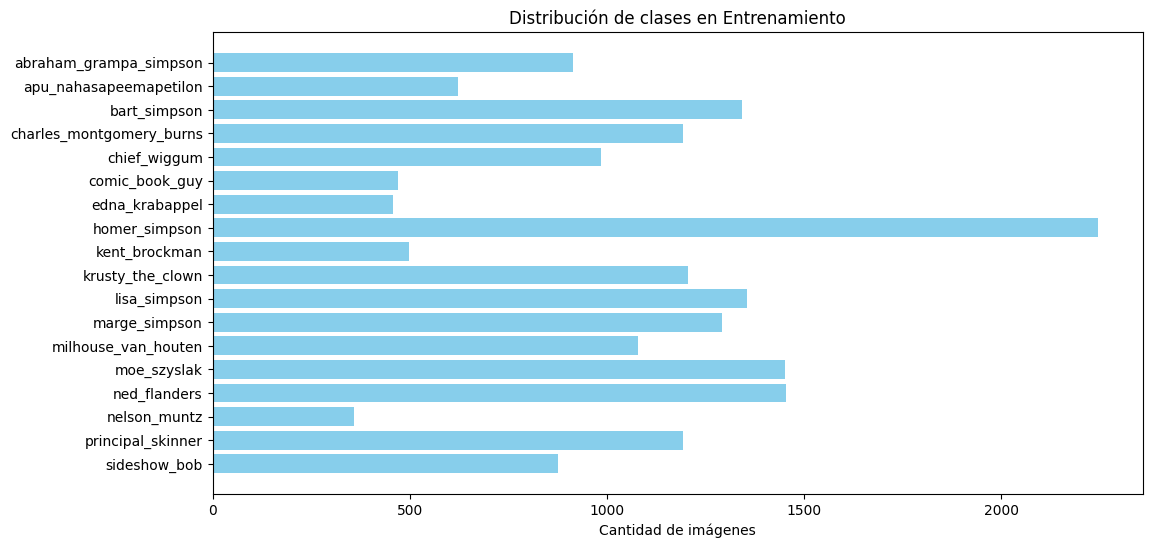

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Contar frecuencias de cada clase
clases, conteos = np.unique(y_train, return_counts=True)
nombres_clases = [MAP_CHARACTERS[c] for c in clases]

# Gráfico de barras horizontales
plt.figure(figsize=(12, 6))
plt.barh(nombres_clases, conteos, color='skyblue')
plt.xlabel('Cantidad de imágenes')
plt.title('Distribución de clases en Entrenamiento')
plt.gca().invert_yaxis()
plt.show()

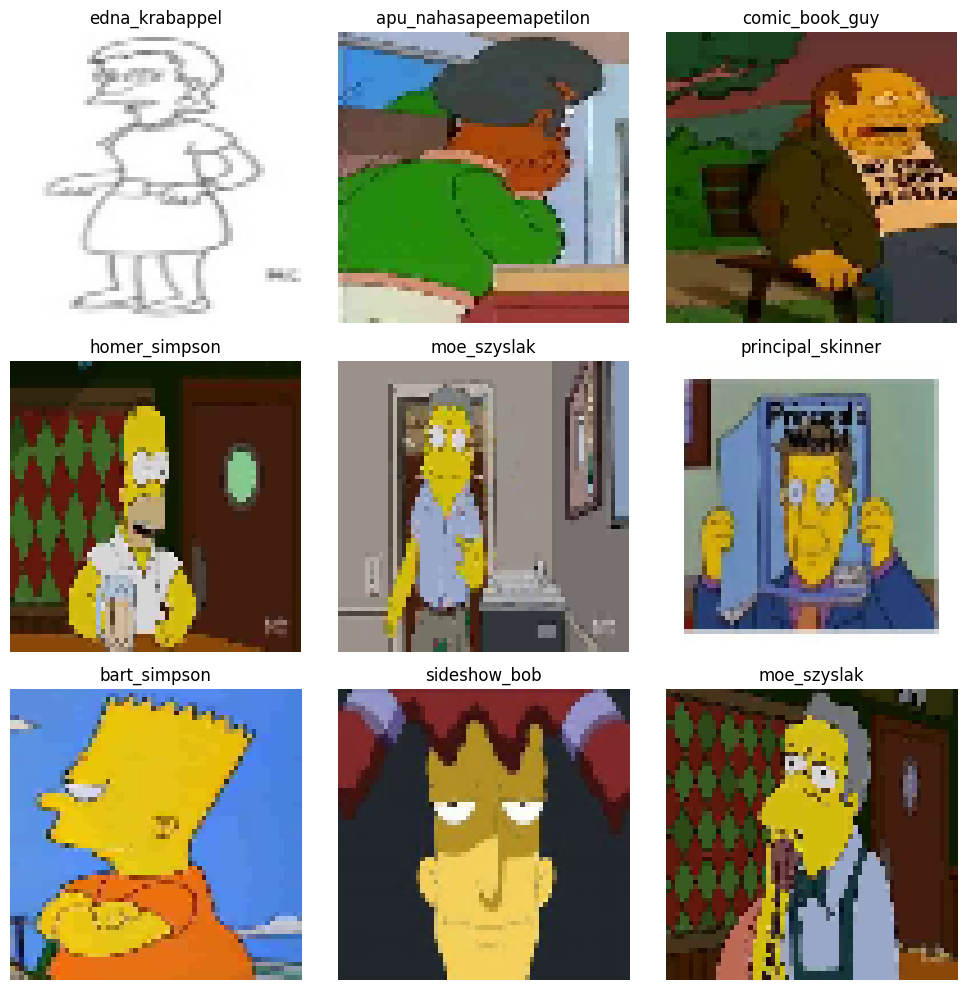

In [ ]:
import random

# Crear cuadrícula 3x3 de imágenes aleatorias
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    idx = random.randint(0, len(X_train) - 1)
    # OpenCV carga en BGR, Matplotlib usa RGB. Se requiere conversión.
    img_rgb = cv2.cvtColor(X_train[idx], cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    ax.set_title(MAP_CHARACTERS[y_train[idx]])
    ax.axis('off')

plt.tight_layout()
plt.show()

# Preprocesamiento de Imágenes

In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

#Aleatorizacion, evita sesgos al entrenar ya que las imágenes se cargaron secuencialmente personaje a personaje.
perm = np.random.permutation(len(X_train))
X_train, y_train = X_train[perm], y_train[perm]
#Escala el valor de los píxeles de 0-255 a un rango de 0.0-1.0.
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
#one hot encoding
y_train = to_categorical(y_train, num_classes=18)
y_test = to_categorical(y_test, num_classes=18)
#Partición Entrenamiento/Validación, división 80/20
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

BatchNormalization(), Normaliza los datos provenientes de la capa anterior para que tengan media 0 y varianza 1. Estabiliza los gradientes y acelera drásticamente la velocidad de convergencia del modelo.

MaxPooling2D((2, 2)), Reduce a la mitad las dimensiones espaciales de la imagen (alto y ancho) quedándose solo con el valor más alto de cada bloque de 2x2. Reduce la carga computacional y hace que el modelo sea invariante a pequeñas traslaciones, por ejemplo detecta un ojo sin importar donde este.

Los filtros se duplican porque el maxpooling reduce la imagen a la mitad, asi no se pierde capacidad de representación

padding='same' rellena con 0 el espacio que quito el kernel

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import SGD

# 1. Modelo MLP
mlp_model = Sequential([
    Flatten(input_shape=(64, 64, 3)),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dense(18, activation='softmax')
])

mlp_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 2. Modelo CNN
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)), #32 filtros de 3x3
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(18, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


# 3. Modelo CNN Arquitectura Alternativa
cnn_model_2 = Sequential([
    Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(64, 64, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2), #se agrega dropout en todos los bloques

    Conv2D(64, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    Conv2D(128, (3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.4),

    Conv2D(256, (3, 3), padding='same', activation='relu'), #al tener mas filtros, combinan los patrones básicos para entender conceptos abstractos y complejos
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.4),

    # Clasificación
    Flatten(),
    # Uso de Regularización L2 en la capa densa para penalizar pesos grandes
    Dense(512, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5), # Dropout fuerte para la capa fully connected
    Dense(18, activation='softmax')
])

# Cambio de hiperparámetros: Uso de SGD con momentum en lugar de Adam
optimizador_sgd = SGD(learning_rate=0.01, momentum=0.9)
cnn_model_2.compile(optimizer=optimizador_sgd, loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Entrenamiento y evaluación

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
#Aumento de datos (data augmentation)
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1, #10%
    height_shift_range=0.1,
    horizontal_flip=True #modo espejo izquierda derecha
)
datagen.fit(X_train)

#calcular los pesos de penalización de forma manual para el class weight porque no me dejo poner el class_weight=balanced
pesos = {i: len(y_train) / (18 * cant) for i, cant in enumerate(y_train.sum(axis=0))}

#Entrenamiento mlp
hist_mlp = mlp_model.fit(
    X_train, y_train,
    batch_size=64,
    epochs=20,
    validation_data=(X_val, y_val),
    class_weight=pesos
)
#Entrenamiento cnn
hist_cnn = cnn_model.fit(
    datagen.flow(X_train, y_train, batch_size=64),
    epochs=30,
    validation_data=(X_val, y_val),
    class_weight=pesos #por esto paso de 0.90 a 0.95 f1
)

# Entrenamiento del segundo modelo CNN
hist_cnn_2 = cnn_model_2.fit(
    datagen.flow(X_train, y_train, batch_size=64),
    epochs=30,
    validation_data=(X_val, y_val),
    verbose=1
)#no se añadio el class_weight para experimentar

#Evaluacion
loss_mlp, acc_mlp = mlp_model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy Test MLP: {acc_mlp*100:.2f}%")

loss_cnn, acc_cnn = cnn_model.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy Test CNN: {acc_cnn*100:.2f}%")

loss_cnn2, acc_cnn2 = cnn_model_2.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy Test CNN 2 (Profunda + SGD): {acc_cnn2*100:.2f}%")

Epoch 1/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.1062 - loss: 3.0327 - val_accuracy: 0.1535 - val_loss: 2.6325
Epoch 2/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1384 - loss: 2.6269 - val_accuracy: 0.2037 - val_loss: 2.5032
Epoch 3/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1657 - loss: 2.5465 - val_accuracy: 0.2474 - val_loss: 2.4798
Epoch 4/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1826 - loss: 2.4994 - val_accuracy: 0.2543 - val_loss: 2.4033
Epoch 5/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1997 - loss: 2.4576 - val_accuracy: 0.2619 - val_loss: 2.4038
Epoch 6/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2136 - loss: 2.4191 - val_accuracy: 0.2285 - val_loss: 2.4326
Epoch 7/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2213 - loss: 2.3976 - val_accuracy: 0.3051 - val_loss: 2.3184
Epoch 8/20
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.2293 - loss: 2.3800 - val_accuracy: 0

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Obtener predicciones
y_pred_mlp = np.argmax(mlp_model.predict(X_test), axis=1)
y_pred_cnn = np.argmax(cnn_model.predict(X_test), axis=1)
y_pred_cnn2 = np.argmax(cnn_model_2.predict(X_test), axis=1)

y_true = np.argmax(y_test, axis=1)

# Nombres de las 18 clases en orden
nombres_clases = [MAP_CHARACTERS[i] for i in range(18)]

print("--- REPORTE POR CLASE: MLP ---")
print(classification_report(y_true, y_pred_mlp, target_names=nombres_clases))

print("\n--- REPORTE POR CLASE: CNN ---")
print(classification_report(y_true, y_pred_cnn, target_names=nombres_clases))

print("\n--- REPORTE POR CLASE: CNN 2 (Profunda + SGD) ---")
print(classification_report(y_true, y_pred_cnn2, target_names=nombres_clases))

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
--- REPORTE POR CLASE: MLP ---
                          precision    recall  f1-score   support

  abraham_grampa_simpson       0.24      0.42      0.31        48
  apu_nahasapeemapetilon       0.43      0.46      0.45        50
            bart_simpson       0.33      0.34      0.33        50
charles_montgomery_burns       0.34      0.23      0.28        48
            chief_wiggum       0.47      0.54      0.50        50
          comic_book_guy       0.66      0.47      0.55        49
          edna_krabappel       0.78      0.36      0.49        50
           homer_simpson       0.39      0.22      0.28        50
           kent_brockman       0.78      0.84      0.81        50
        krusty_the_clown       0.43      0.62      0.51        50
            lisa_simpson       0.62      0.10      0.17        50
           marge_simpson       0.95      0.40      0.56  

**Desempeño por ClasesMLP:** Las mejores fueron Kent Brockman y Sideshow Bob (paletas de color y siluetas muy distintivas). Las peores fueron Lisa Simpson (F1-Score de 0.17, con un Recall de apenas 0.10), seguido de Charles Montgomery Burns (0.28) y Homer Simpson (0.28), antes del balanceo, las clases minoritarias como nelson tenian 0 en todo.

**CNN 1:** Las mejores fueron Apu, Krusty y comic book guy, con clasificaciones casi perfectas. Las peores fueron Homer y Lisa, que acumularon la mayor cantidad de pequeños errores cruzados.

**CNN 2:** Las mejores fueron Krusty y Milhouse. La peor fue Bart, ya que el modelo se volvió demasiado conservador y dejó escapar falsos negativos, puede deberse a que tiene menos imagenes y no se le aplico un balanceo como en el cnn 1.

* Si precision es bajo, genera falsos positivos
* Si recall es bajo, genera falsos positivos
* f1 es un promedio armonico
* accuracy es lo que clasifico/total, si hay clases desbalanceadas puede ser engañoso

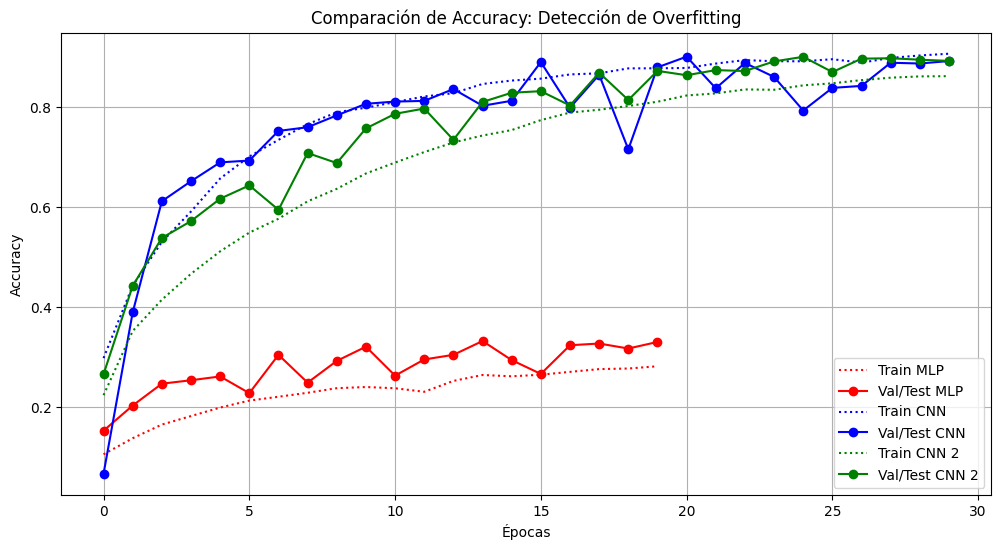

In [ ]:
plt.figure(figsize=(12, 6))

# Curvas MLP
plt.plot(hist_mlp.history['accuracy'], label='Train MLP', color='red', linestyle=':')
plt.plot(hist_mlp.history['val_accuracy'], label='Val/Test MLP', color='red', marker='o')

# Curvas CNN
plt.plot(hist_cnn.history['accuracy'], label='Train CNN', color='blue', linestyle=':')
plt.plot(hist_cnn.history['val_accuracy'], label='Val/Test CNN', color='blue', marker='o')

# Curvas CNN 2
plt.plot(hist_cnn_2.history['accuracy'], label='Train CNN 2', color='green', linestyle=':')
plt.plot(hist_cnn_2.history['val_accuracy'], label='Val/Test CNN 2', color='green', marker='o')

plt.title('Comparación de Accuracy: Detección de Overfitting')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Calcular promedios globales (macro)
resultados = {
    'Métrica': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Modelo MLP': [
        f"{acc_mlp*100:.2f}%",
        f"{precision_score(y_true, y_pred_mlp, average='macro'):.4f}",
        f"{recall_score(y_true, y_pred_mlp, average='macro'):.4f}",
        f"{f1_score(y_true, y_pred_mlp, average='macro'):.4f}"
    ],
    'Modelo CNN': [
        f"{acc_cnn*100:.2f}%",
        f"{precision_score(y_true, y_pred_cnn, average='macro'):.4f}",
        f"{recall_score(y_true, y_pred_cnn, average='macro'):.4f}",
        f"{f1_score(y_true, y_pred_cnn, average='macro'):.4f}"
    ],
    'Modelo CNN 2': [
        f"{acc_cnn2*100:.2f}%",
        f"{precision_score(y_true, y_pred_cnn2, average='macro'):.4f}",
        f"{recall_score(y_true, y_pred_cnn2, average='macro'):.4f}",
        f"{f1_score(y_true, y_pred_cnn2, average='macro'):.4f}"
    ]
}

# Crear y mostrar tabla
df_resumen = pd.DataFrame(resultados)
print("\n--- TABLA RESUMEN DE MODELOS ---")
display(df_resumen)


--- TABLA RESUMEN DE MODELOS ---


,Métrica,Modelo MLP,Modelo CNN,Modelo CNN 2
0,Accuracy,41.57%,95.39%,94.27%
1,Precision (Macro),0.4703,0.9547,0.9458
2,Recall (Macro),0.4160,0.9541,0.9427
3,F1-Score (Macro),0.4144,0.9538,0.9426


# Comparación General y Métricas

**Modelo MLP: Obtuvo un rendimiento ineficiente (~41% de exactitud), siendo en la práctica peor que lanzar una moneda para ciertas clases. Al aplanar los píxeles desde el principio, destruye la estructura espacial 2D de la imagen, volviéndolo incapaz de reconocer formas o bordes.**

**Modelo CNN 1 (Base/Adam): Logró el mejor rendimiento global (~95% de exactitud). Extrajo patrones visuales con gran eficacia y aprendió rápidamente, aunque presentó ligeras oscilaciones en validación.**

**Modelo CNN 2 (Profunda/SGD): Mostró un desempeño excelente (~94%). Si bien su exactitud final es levemente inferior a la CNN 1, su aprendizaje fue significativamente más estable. Las técnicas aplicadas (SGD, Regularización L2 y Dropout progresivo) anularon cualquier riesgo de overfitting.**

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Total de errores de la CNN 1 en el test set: 41 de 890 imágenes.


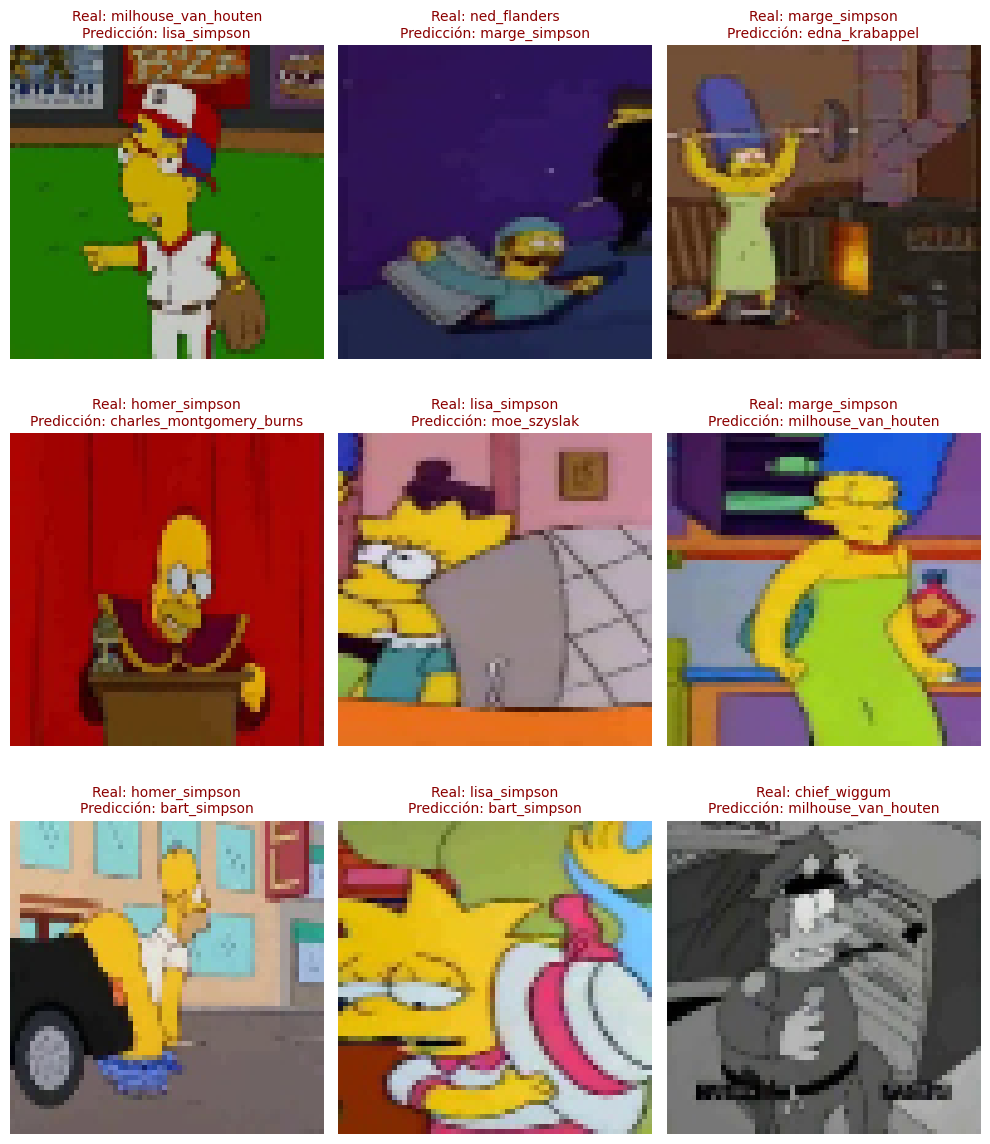

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Obtener los índices donde la predicción de la CNN 1 no coincide con la etiqueta real
y_pred_cnn = np.argmax(cnn_model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)
errores_idx = np.where(y_pred_cnn != y_true)[0]

print(f"Total de errores de la CNN 1 en el test set: {len(errores_idx)} de {len(y_test)} imágenes.")

# Visualizar una cuadrícula 3x3 con los primeros 9 errores
fig, axes = plt.subplots(3, 3, figsize=(10, 12))
for i, ax in enumerate(axes.flat):
    if i < len(errores_idx):
        idx = errores_idx[i]
        # Convertir de BGR (formato de lectura de OpenCV) a RGB (para Matplotlib)
        img_rgb = cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)
        verdadero = MAP_CHARACTERS[y_true[idx]]
        predicho = MAP_CHARACTERS[y_pred_cnn[idx]]

        ax.set_title(f"Real: {verdadero}\nPredicción: {predicho}", color='darkred', fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.show()

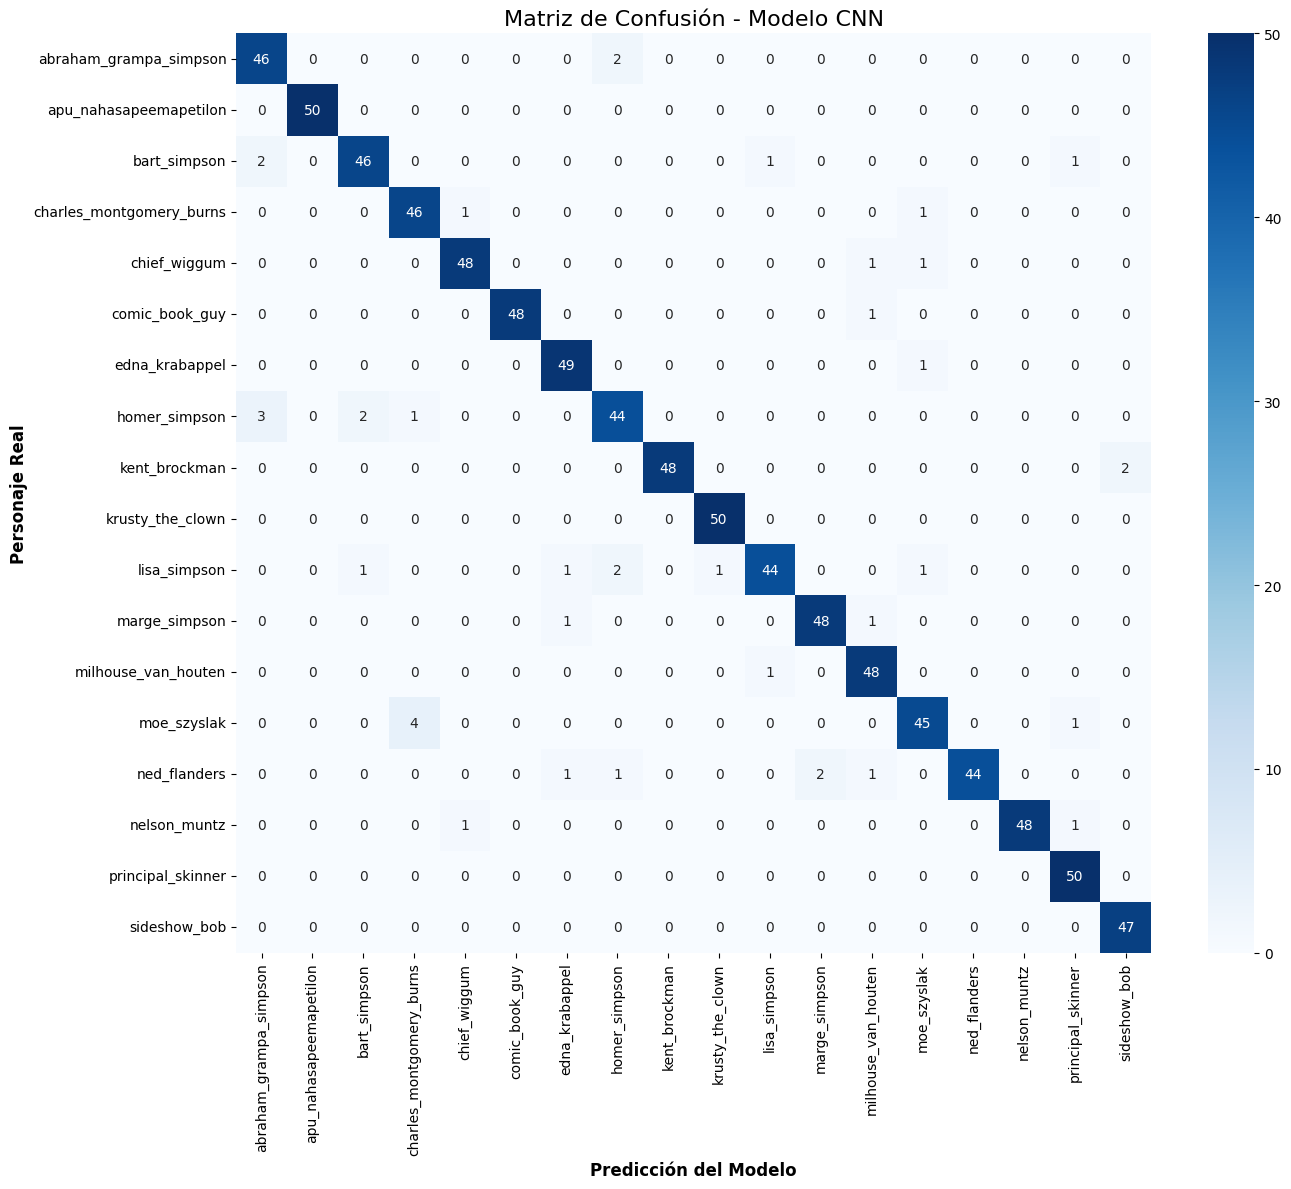

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Calcular la matriz de confusión usando las predicciones de la CNN principal
cm = confusion_matrix(y_true, y_pred_cnn)

# Configurar el tamaño de la figura
plt.figure(figsize=(14, 12))

# Crear el mapa de calor con seaborn
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases)

plt.title('Matriz de Confusión - Modelo CNN', fontsize=16)
plt.ylabel('Personaje Real', fontsize=12, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#Análisis de la Matriz de Confusión (CNN 1)
**La matriz evidencia un modelo robusto con una diagonal principal sólidamente oscura, pero revela patrones de confusión muy específicos ligados a la animación de la serie:**

**Moe Szyslak:** Presenta la mayor confusión individual del modelo, siendo etiquetado erróneamente como Charles Montgomery Burns en 4 ocasiones.

**Homer Simpson**: Se confunde directamente con sus familiares por la similitud en la forma base y paleta de colores. Fue clasificado como Abraham Grampa Simpson 3 veces y como Bart Simpson 2 veces.

**Lisa Simpson:** A pesar de su diseño distintivo, el modelo la confundió con Homer Simpson en 2 imágenes.

**Conclusion:** Las cnn se benefician de las imagenes con mayores resolucion porque detectan los bordes, a diferencia de los mlp que tienden al overfiting cuando tienen demasiados valores de entrada. Ademas, las cnn mantienen las relaciones espaciales.

Los mejores modelos fueron las cnns, el cnn 1 tiene mejores resultados pero el cnn 2 es mas estable, ambos tiene buena generalizacion y detectan a los personajes en distintas poses pero se confunden cuando las apariencias de los personajes son diferentes a las usuales